In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
results_dir = os.path.join(project_dir, '...')

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## cortical thickness
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige_durill.csv'), index_col=0)

## subcortical volume
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige_durill.csv'), index_col=0)


In [1]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of age in males

In [4]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        male_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col="durill", ao_col="ao", age_col="Age",
            sex_col="Sex", icv_col="ICV", gender="male", correlate_variable="age")

In [5]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

male_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        male_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'

        stacked_values = []
        for epi in epi_types:
            stacked_values.append(male_diagnosis[epi][biomarker][metric_key])
        
        male_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

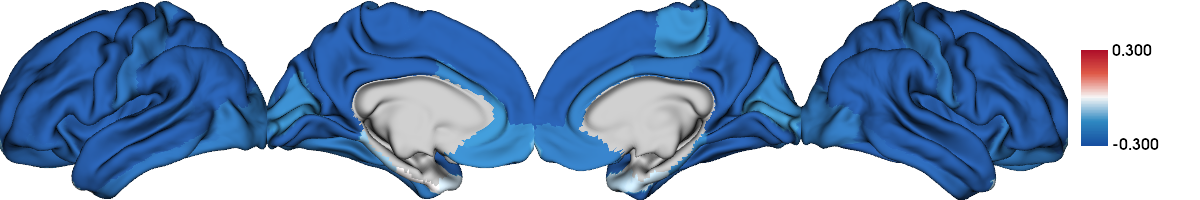

In [ ]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

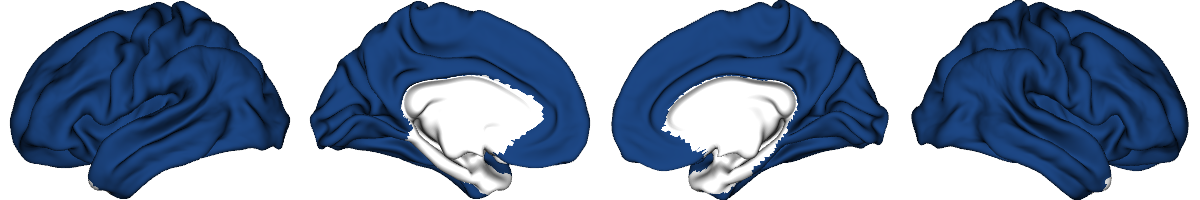

In [8]:
# plot p-sig regions

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [9]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalanteriorcingulate', 'L_caudalmiddlefrontal',
       'L_cuneus', 'L_fusiform', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_isthmuscingulate', 'L_lateraloccipital', 'L_lateralorbitofrontal',
       'L_lingual', 'L_medialorbitofrontal', 'L_middletemporal',
       'L_paracentral', 'L_parsopercularis', 'L_parsorbitalis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_frontalpole', 'L_transversetemporal', 'L_insula',
       'R_bankssts', 'R_caudalanteriorcingulate', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_lateraloccipital', 'R_lateralorbitofrontal',
       'R_lingual', 'R_medialorbitofrontal', 'R_middletemporal',
       

In [10]:
len(q_ctx_tle[q_ctx_tle < 0.05])

63

In [11]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_ctx'][0].min(), male_metrics['cohen_ctx'][0].max()

(-0.5188068610358347, 0.0068676894391198505)

IGE

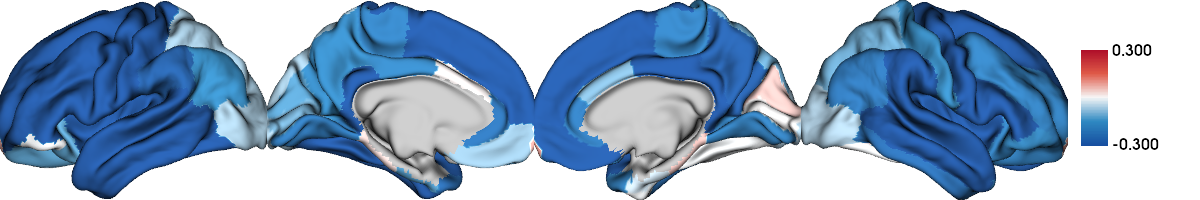

In [ ]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

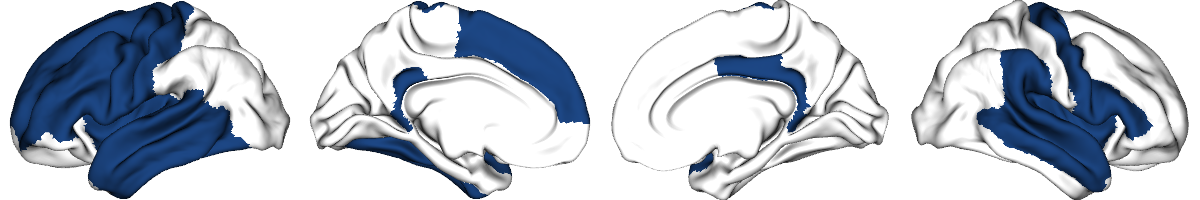

In [16]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [17]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_fusiform',
       'L_inferiortemporal', 'L_isthmuscingulate', 'L_middletemporal',
       'L_parsopercularis', 'L_parstriangularis', 'L_postcentral',
       'L_precentral', 'L_rostralmiddlefrontal', 'L_superiorfrontal',
       'L_superiortemporal', 'L_transversetemporal', 'L_insula', 'R_bankssts',
       'R_isthmuscingulate', 'R_middletemporal', 'R_parsopercularis',
       'R_parstriangularis', 'R_posteriorcingulate', 'R_precentral',
       'R_superiortemporal', 'R_supramarginal', 'R_transversetemporal',
       'R_insula'],
      dtype='object')

In [18]:
len(q_ctx_ige[q_ctx_ige < 0.05])

26

In [19]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_ctx'][1].min(), male_metrics['cohen_ctx'][1].max()

(-0.6671104462228735, 0.08514748543916148)

Subcortical volumes in TLE

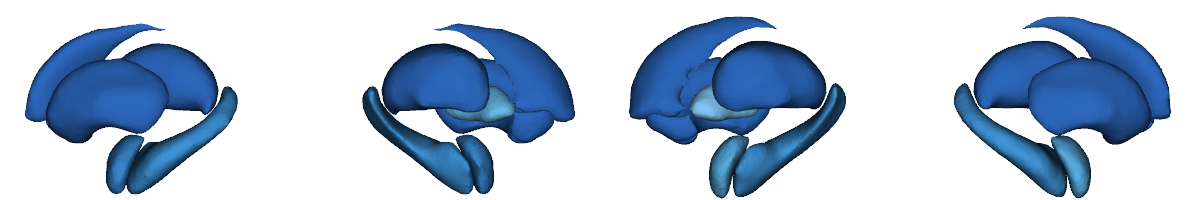

In [21]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

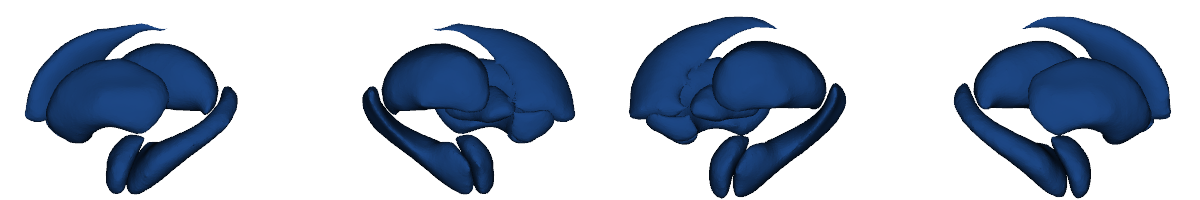

In [22]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [23]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [24]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_sv'][0].min(), male_metrics['cohen_sv'][0].max()

(-0.43572909098421575, -0.10739162356362827)

IGE

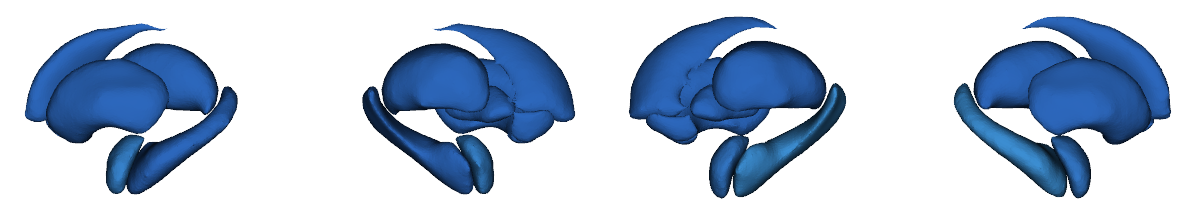

In [27]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

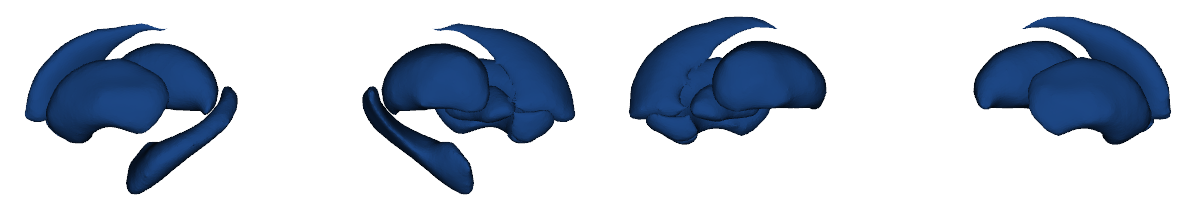

In [28]:
# plot p-sig areas

sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [29]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Laccumb    3.194642e-02
Lcaud      1.461043e-03
Lhippo     1.674241e-02
Lpal       6.936938e-04
Lput       1.596672e-05
Lthal      3.200951e-07
Raccumb    8.087652e-04
Rcaud      2.121792e-03
Rpal       8.087652e-04
Rput       3.483293e-05
Rthal      3.035020e-06
Name: pFDR, dtype: float64

In [30]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_sv'][1].min(), male_metrics['cohen_sv'][1].max()

(-0.8664082128322056, -0.2035529179228258)

## Effects of age in females

In [32]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.clinical_correlate_across_sexes(
            df_name=df_name, durill_col="durill", ao_col="ao", age_col="Age",
            sex_col="Sex", icv_col="ICV", gender="female", correlate_variable="age")

In [33]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

female_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        female_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'

        stacked_values = []
        for epi in epi_types:
            stacked_values.append(female_diagnosis[epi][biomarker][metric_key])
        
        female_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

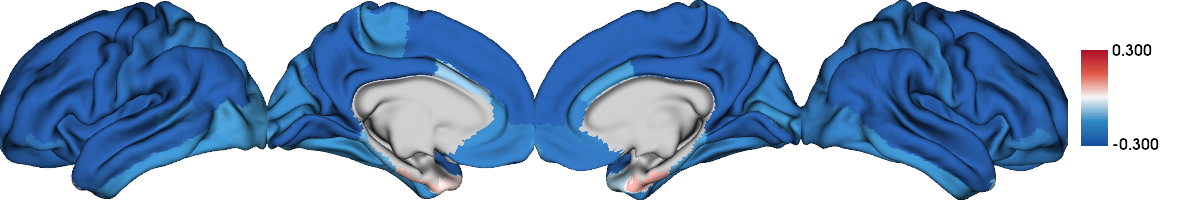

In [34]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

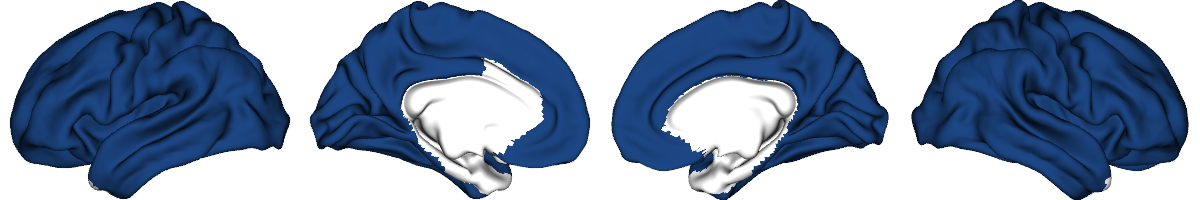

In [36]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [37]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_fusiform',
       'L_inferiorparietal', 'L_inferiortemporal', 'L_isthmuscingulate',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_medialorbitofrontal', 'L_middletemporal', 'L_parahippocampal',
       'L_paracentral', 'L_parsopercularis', 'L_parsorbitalis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralanteriorcingulate', 'L_rostralmiddlefrontal',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_frontalpole', 'L_transversetemporal', 'L_insula',
       'R_bankssts', 'R_caudalanteriorcingulate', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_lateraloccipital', 'R_lateralorbitofrontal',
       'R_lingual', 'R_medialorbitofrontal', 'R_middletemporal',
       'R_parah

In [38]:
len(q_ctx_tle[q_ctx_tle < 0.05])

63

In [39]:
# get the cohen's d values range for TLE in females
female_metrics['cohen_ctx'][0].min(), female_metrics['cohen_ctx'][0].max()

(-0.5004622096680867, 0.0777450276042042)

IGE

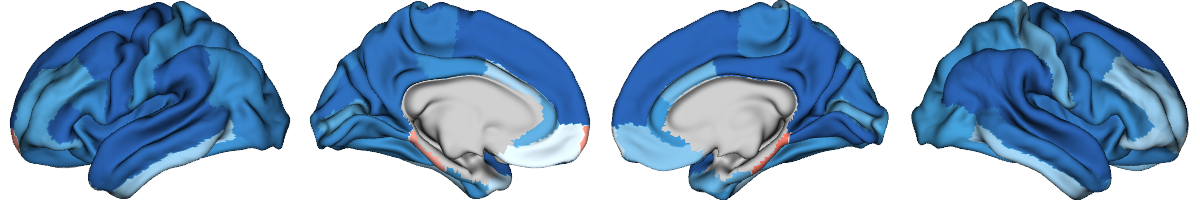

In [41]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

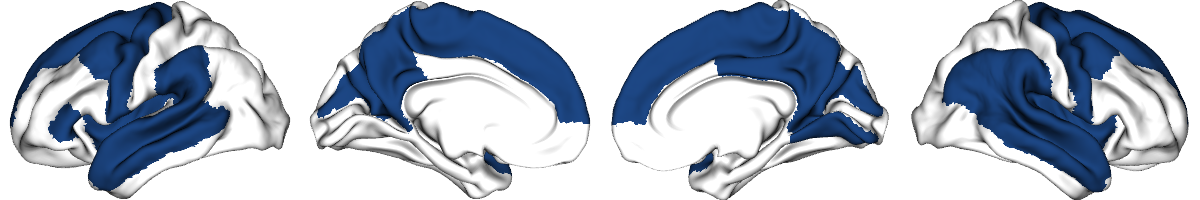

In [42]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [43]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_isthmuscingulate',
       'L_middletemporal', 'L_paracentral', 'L_parstriangularis',
       'L_precentral', 'L_precuneus', 'L_superiorfrontal',
       'L_superiortemporal', 'L_supramarginal', 'L_insula', 'R_bankssts',
       'R_caudalmiddlefrontal', 'R_cuneus', 'R_inferiorparietal',
       'R_isthmuscingulate', 'R_lingual', 'R_middletemporal', 'R_paracentral',
       'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_superiorfrontal', 'R_superiortemporal', 'R_supramarginal',
       'R_transversetemporal', 'R_insula'],
      dtype='object')

In [44]:
len(q_ctx_ige[q_ctx_ige < 0.05])

29

In [45]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_ctx'][1].min(), female_metrics['cohen_ctx'][1].max()

(-0.44881468452999057, 0.13942627486733672)

Subcortical volumes in TLE

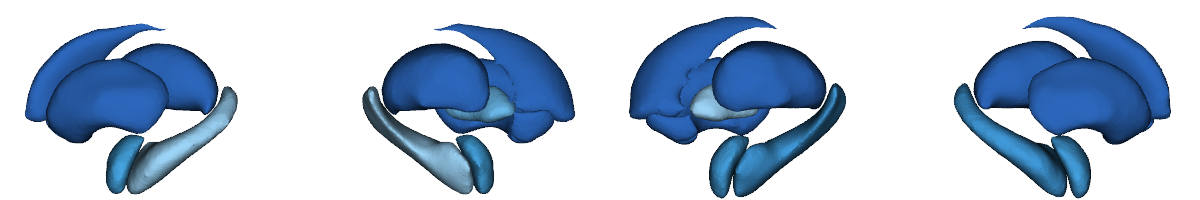

In [49]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

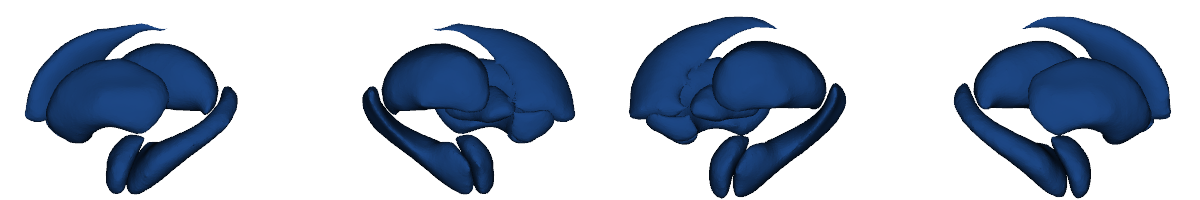

In [50]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [51]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [52]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_sv'][0].min(), female_metrics['cohen_sv'][0].max()

(-0.3823210786844111, -0.08765902854975352)

IGE

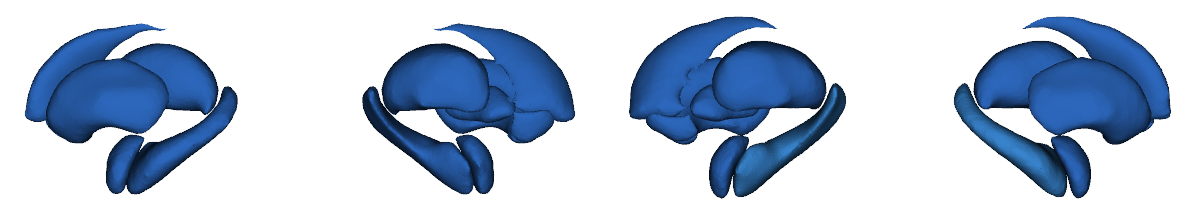

In [54]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

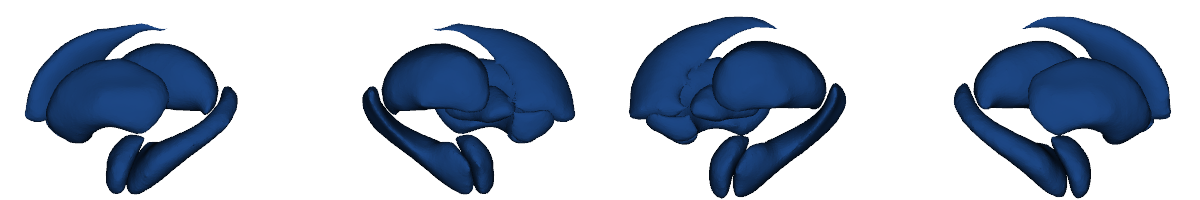

In [55]:
# plot p-sig areas

sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [56]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [57]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_sv'][1].min(), female_metrics['cohen_sv'][1].max()

(-0.6085422809393396, -0.22788370301422148)

## Age, and age-by sex interaction effects

In [59]:
# glm comparison
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction', 'age', 'age_sex_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 14:40:20,493 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-05-28 14:40:20,547 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 14:40:20,732 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 14:40:20,837 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 14:40:20,897 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [60]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['duration']['t_values'],
            results[epi][biomarker]['duration_sex_interaction']['t_values'],
            results[epi][biomarker]['ao']['t_values'],
            results[epi][biomarker]['ao_sex_interaction']['t_values'],
            results[epi][biomarker]['age']['t_values'],
            results[epi][biomarker]['age_sex_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['duration']['q_values'],
            results[epi][biomarker]['duration_sex_interaction']['q_values'],
            results[epi][biomarker]['ao']['q_values'],
            results[epi][biomarker]['ao_sex_interaction']['q_values'],
            results[epi][biomarker]['age']['q_values'],
            results[epi][biomarker]['age_sex_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['duration']['cohen_d'],
            results[epi][biomarker]['duration_sex_interaction']['cohen_d'],
            results[epi][biomarker]['ao']['cohen_d'],
            results[epi][biomarker]['ao_sex_interaction']['cohen_d'],
            results[epi][biomarker]['age']['cohen_d'],
            results[epi][biomarker]['age_sex_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

### TLE results visualization

Sex age interaction effects in cortical thickness

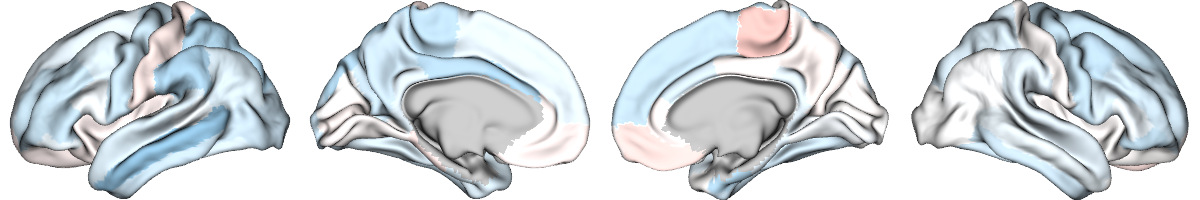

In [61]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao', 'sex + age', 'sex * age']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][5], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

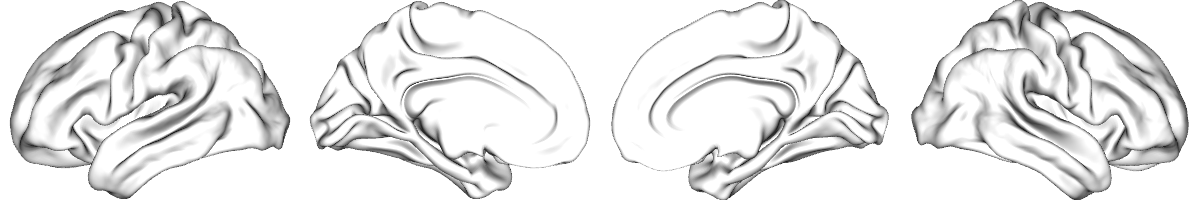

In [62]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][5], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [63]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][5], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [64]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [65]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][5].min(), result_dicts['cohen_tle_ctx'][5].max()

(-0.08368550608188254, 0.0551873304939211)

subcortical volume

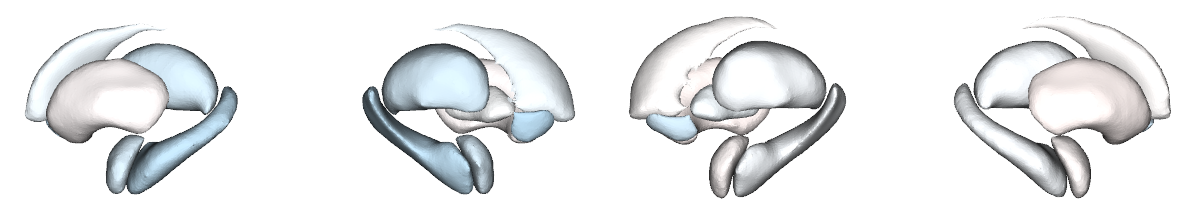

In [67]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao', 'sex + age', 'sex * age']

plot_subcortical(result_dicts['cohen_tle_sv'][5], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


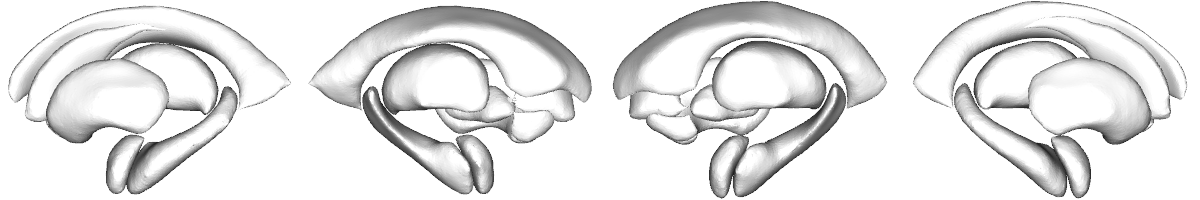

In [68]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [69]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][5], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [70]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [71]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][5].min(), result_dicts['cohen_tle_sv'][5].max()

(-0.05796447097010686, 0.012422549707245326)

### Visualization in IGE

Sex age interaction effects in cortical thickness

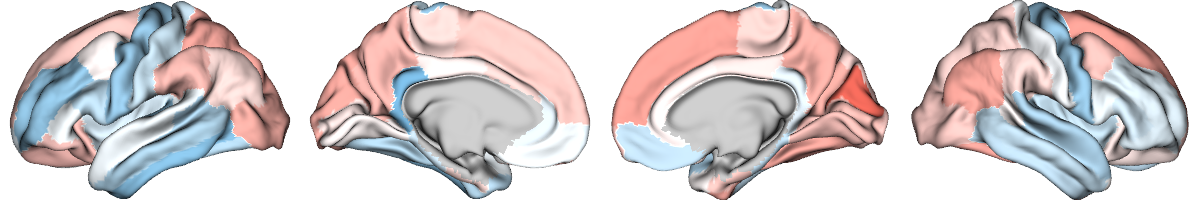

In [73]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao', 'sex + age', 'sex * age']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][5], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

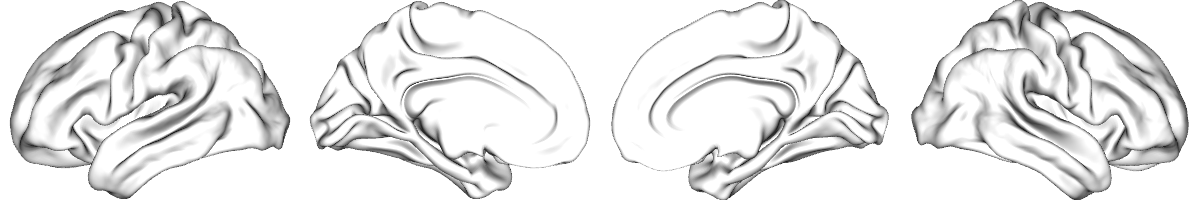

In [74]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][5], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [75]:
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao', 'sex + age', 'sex * age']

## Check which areas are significant in epilepsy
q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][5], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index([], dtype='object')

In [76]:
len(q_ctx_ige[q_ctx_ige < 0.05])

0

In [77]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][5].min(), result_dicts['cohen_ige_ctx'][5].max()

(-0.10573050590423495, 0.15454254619655874)

Sex age interaction in subcortical volume

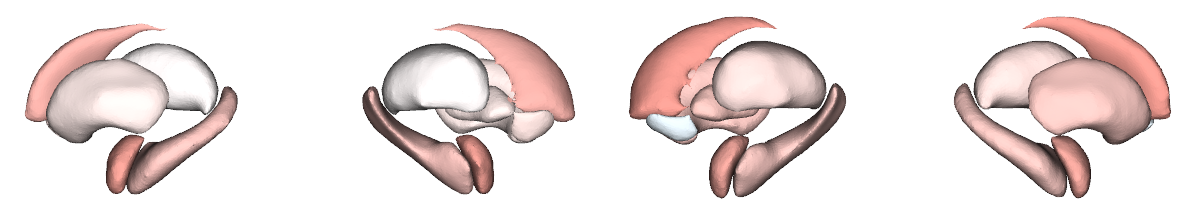

In [79]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao', 'sex + age', 'sex * age']

plot_subcortical(result_dicts['cohen_ige_sv'][5], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

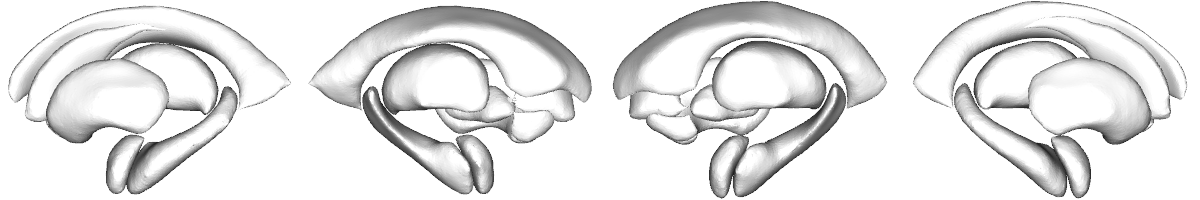

In [80]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_ige_sv'][5] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [81]:
## Check which areas are significant in epilepsy
q_sv_ige = pd.Series(result_dicts['q_ige_sv'][5], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index([], dtype='object')

In [82]:
len(q_sv_ige[q_sv_ige < 0.05])

0

In [83]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][5].min(), result_dicts['cohen_ige_sv'][5].max()

(-0.022050252212432987, 0.09940860654302094)